# Manifiesto de datos con SHA-256: integridad, autenticidad y sus límites

**Perfil:** Liderazgo de datos y gobierno  
**Datos:** sintéticos con semilla fija; se conoce el proceso generador, así que se puede comprobar si el método recupera la verdad.

## Pregunta que guía el notebook

¿Cómo se sabe que un archivo de datos es el mismo que se usó para entrenar un modelo o reportar a un regulador? Un **manifiesto** de hashes responde a esa pregunta, pero con matices: un hash detecta cambios de *bytes*, no de *significado*; protege contra el error, no contra un adversario que también edita el manifiesto; y no todas las sumas de verificación sirven.

## Recorrido

1. Propiedades del hash: **efecto avalancha** medido y determinismo.
2. **Manifiesto** (ruta, SHA-256, bytes, filas) y verificación que distingue modificado, faltante, nuevo y **renombrado**.
3. **Falsos positivos de integridad:** fin de línea, orden de columnas; hash **semántico** y su tolerancia numérica.
4. **Árbol de Merkle:** raíz única, prueba de inclusión en $\log n$ hashes y detección de manipulación.
5. **Autenticidad del manifiesto:** quién puede reescribirlo y cómo lo evita un HMAC.
6. **¿Por qué no CRC32?** Se falsifica a propósito un archivo con el mismo CRC; **hash truncado y cumpleaños**: colisiones medidas frente a la teoría.
7. Lectura por bloques (memoria constante) y pruebas.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
import hashlib, hmac, io, json, os, shutil, tempfile, time, zlib
from pathlib import Path

## 2. Efecto avalancha

Una buena función hash cambia, al invertir **un solo bit** de la entrada, cerca de la mitad de los 256 bits de la salida (cada bit de salida cambia con probabilidad 1/2, de forma casi independiente). Si $D$ es el número de bits que cambian, $D\sim\text{Bin}(256,\tfrac12)$: media 128, desvío 8. Se mide con 2.000 mensajes de 1 KB y se compara con una función **no criptográfica** trivial (suma de bytes módulo $2^{32}$) como contraste.

SHA-256: bits cambiados  media=128.07 (teorico 128)  sd=7.89 (teorico 8.00)  min=102  max=155
Suma mod 2^32: bits cambiados  media=1.99 de 32 (fraccion 0.06)  sd=1.54


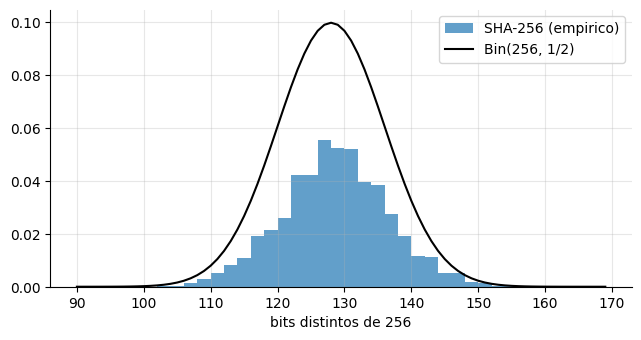

In [2]:
def bits_distintos(a: bytes, b: bytes) -> int: return bin(int.from_bytes(a, "big") ^ int.from_bytes(b, "big")).count("1")
rg = np.random.default_rng(SEED); dif = []; dif_suma = []
def suma32(m: bytes) -> bytes: return (sum(m) % 2 ** 32).to_bytes(4, "big")
for _ in range(2000):
    m = bytearray(rg.bytes(1024)); m2 = bytearray(m); k = int(rg.integers(0, 1024 * 8)); m2[k // 8] ^= 1 << (k % 8)
    dif.append(bits_distintos(hashlib.sha256(m).digest(), hashlib.sha256(m2).digest())); dif_suma.append(bits_distintos(suma32(bytes(m)), suma32(bytes(m2))))
dif = np.array(dif); dif_suma = np.array(dif_suma)
print(f"SHA-256: bits cambiados  media={dif.mean():.2f} (teorico 128)  sd={dif.std():.2f} (teorico 8.00)  min={dif.min()}  max={dif.max()}")
print(f"Suma mod 2^32: bits cambiados  media={dif_suma.mean():.2f} de 32 (fraccion {dif_suma.mean() / 32:.2f})  sd={dif_suma.std():.2f}")
fig, ax = plt.subplots(figsize=(7.5, 3.6)); ax.hist(dif, bins=np.arange(90, 170, 2), density=True, alpha=.7, label="SHA-256 (empirico)")
x = np.arange(90, 170); from scipy import stats; ax.plot(x, stats.binom.pmf(x, 256, .5) * 2, "k-", label="Bin(256, 1/2)"); ax.set_xlabel("bits distintos de 256"); ax.legend(); plt.show()

In [3]:
print("Lectura:")
print(f"  El numero de bits cambiados por SHA-256 tiene media {dif.mean():.1f} y desvio {dif.std():.1f}, casi identicos a los de una Binomial(256, 1/2) (128 y 8): un cambio de 1 bit en 8.192 reescribe la mitad del resumen.")
print(f"  La suma de bytes cambia {dif_suma.mean():.1f} bits de 32: un cambio de un bit mueve la suma en +-2^k y deja casi todos los bits iguales; es un 'checksum' debil para detectar manipulaciones.")

Lectura:
  El numero de bits cambiados por SHA-256 tiene media 128.1 y desvio 7.9, casi identicos a los de una Binomial(256, 1/2) (128 y 8): un cambio de 1 bit en 8.192 reescribe la mitad del resumen.
  La suma de bytes cambia 2.0 bits de 32: un cambio de un bit mueve la suma en +-2^k y deja casi todos los bits iguales; es un 'checksum' debil para detectar manipulaciones.


## 3. Manifiesto y verificación

El manifiesto lista para cada archivo su ruta relativa, SHA-256, tamaño y número de filas. La verificación compara el estado actual con el manifiesto y clasifica cada archivo como `OK`, `MODIFICADO`, `FALTA`, `NUEVO` o `RENOMBRADO` (mismo hash en otra ruta). Se trabaja en un directorio temporal con 6 archivos CSV sintéticos.

In [4]:
def sha256_archivo(ruta, bloque=1 << 20):
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for b in iter(lambda: f.read(bloque), b""): h.update(b)
    return h.hexdigest()

def contar_filas(ruta):
    with open(ruta, "rb") as f: return max(sum(1 for _ in f) - 1, 0)

def construir_manifiesto(raiz):
    raiz = Path(raiz); filas = []
    for p in sorted(raiz.rglob("*.csv")):
        filas.append({"ruta": p.relative_to(raiz).as_posix(), "sha256": sha256_archivo(p), "bytes": p.stat().st_size, "filas": contar_filas(p)})
    return pd.DataFrame(filas)

def verificar(raiz, man):
    actual = construir_manifiesto(raiz); hallazgos = []
    por_ruta = man.set_index("ruta"); act_ruta = actual.set_index("ruta")
    for r in por_ruta.index:
        if r not in act_ruta.index:
            nuevo = actual[(actual.sha256 == por_ruta.loc[r, "sha256"]) & (~actual.ruta.isin(por_ruta.index))]
            hallazgos.append(("RENOMBRADO", r, nuevo.ruta.iloc[0]) if len(nuevo) else ("FALTA", r, ""))
        elif act_ruta.loc[r, "sha256"] != por_ruta.loc[r, "sha256"]: hallazgos.append(("MODIFICADO", r, ""))
    renombrados_destino = {h[2] for h in hallazgos if h[0] == "RENOMBRADO"}
    for r in act_ruta.index:
        if r not in por_ruta.index and r not in renombrados_destino: hallazgos.append(("NUEVO", r, ""))
    return pd.DataFrame(hallazgos, columns=["hallazgo", "ruta", "destino"])

def crear_datos(raiz, seed=0):
    rg = np.random.default_rng(seed); raiz = Path(raiz)
    for nombre in ("macro", "precios", "tasas", "cartera", "clima", "ventas"):
        pd.DataFrame({"id": np.arange(200), "valor": rg.normal(size=200).round(6), "grupo": rg.choice(list("ABC"), 200)}).to_csv(raiz / f"{nombre}.csv", index=False)

tmp = Path(tempfile.mkdtemp()); crear_datos(tmp); man = construir_manifiesto(tmp)
print(man.assign(sha256=man.sha256.str[:16] + "...").to_string(index=False))
print("\nVerificacion inicial:", "sin hallazgos" if verificar(tmp, man).empty else verificar(tmp, man))

       ruta              sha256  bytes  filas
cartera.csv a749575fbedbbf97...   3000    200
  clima.csv 1bc6597936325491...   2979    200
  macro.csv d3c2e7ccae3c7dc7...   2975    200
precios.csv d3a2a151e84921a4...   2990    200
  tasas.csv de1771f0d1e60a36...   2979    200
 ventas.csv 325bf2661aadb74c...   2981    200

Verificacion inicial: sin hallazgos


In [5]:
escenarios = {}
def probar(nombre, accion):
    d = Path(tempfile.mkdtemp()); crear_datos(d); m = construir_manifiesto(d); accion(d); v = verificar(d, m); escenarios[nombre] = v; shutil.rmtree(d); return v

def editar_un_byte(d):
    b = bytearray((d / "macro.csv").read_bytes()); b[100] = ord("9") if b[100] != ord("9") else ord("8"); (d / "macro.csv").write_bytes(bytes(b))
probar("un byte alterado", editar_un_byte)
probar("archivo borrado", lambda d: (d / "tasas.csv").unlink())
probar("archivo nuevo", lambda d: (d / "extra.csv").write_text("a,b\n1,2\n"))
probar("renombrado", lambda d: (d / "clima.csv").rename(d / "clima_v2.csv"))
probar("solo cambia la fecha (touch)", lambda d: os.utime(d / "precios.csv", (1, 1)))
def dos_cosas(d): editar_un_byte(d); (d / "ventas.csv").unlink(); (d / "otro.csv").write_text("x\n1\n")
probar("modificado + borrado + nuevo", dos_cosas)
res = pd.DataFrame({k: ["; ".join(f"{h}:{r}" for h, r in zip(v.hallazgo, v.ruta)) or "sin hallazgos"] for k, v in escenarios.items()}).T.rename(columns={0: "hallazgos"}); res

,hallazgos
un byte alterado,MODIFICADO:macro.csv
archivo borrado,FALTA:tasas.csv
archivo nuevo,NUEVO:extra.csv
renombrado,RENOMBRADO:clima.csv
solo cambia la fecha (touch),sin hallazgos
modificado + borrado + nuevo,MODIFICADO:macro.csv; FALTA:ventas.csv; NUEVO:...


In [6]:
print("Lectura:")
print(f"  Un solo byte alterado se detecta ({escenarios['un byte alterado'].hallazgo.tolist()}); el borrado, el archivo nuevo y el renombrado se clasifican correctamente.")
print(f"  Cambiar solo la fecha de modificacion NO genera hallazgo: el hash depende del contenido, no de los metadatos (una verificacion por mtime daria un falso positivo y no detectaria un cambio con mtime restaurado).")
print(f"  Escenario combinado: {escenarios['modificado + borrado + nuevo'].hallazgo.tolist()}.")

Lectura:
  Un solo byte alterado se detecta (['MODIFICADO']); el borrado, el archivo nuevo y el renombrado se clasifican correctamente.
  Cambiar solo la fecha de modificacion NO genera hallazgo: el hash depende del contenido, no de los metadatos (una verificacion por mtime daria un falso positivo y no detectaria un cambio con mtime restaurado).
  Escenario combinado: ['MODIFICADO', 'FALTA', 'NUEVO'].


## 4. Cuando el hash dice «cambió» pero los datos son los mismos

El hash detecta cualquier cambio de bytes, incluidos los **irrelevantes**: terminadores de línea CRLF frente a LF, orden de columnas, número de decimales. Se genera el mismo conjunto de datos de cuatro maneras y se comparan el hash crudo y un **hash semántico** (forma canónica: columnas ordenadas, filas ordenadas por clave, números redondeados a $d$ decimales, saltos de línea `\n`).

In [7]:
base = pd.DataFrame({"id": np.arange(300), "x": np.random.default_rng(1).normal(size=300), "g": np.random.default_rng(2).choice(list("ABC"), 300)})
def a_bytes(df, **kw): return df.to_csv(index=False, **kw).encode()
variantes = {"original": a_bytes(base), "CRLF": a_bytes(base, lineterminator="\r\n"), "columnas permutadas": a_bytes(base[["g", "x", "id"]]), "filas barajadas": a_bytes(base.sample(frac=1, random_state=0)), "precision 6 decimales": a_bytes(base.round(6))}

def hash_semantico(b: bytes, decimales=6, clave="id"):
    df = pd.read_csv(io.BytesIO(b)); df = df[sorted(df.columns)].sort_values(clave).reset_index(drop=True)
    num = df.select_dtypes("number").columns; df[num] = df[num].round(decimales)
    return hashlib.sha256(df.to_csv(index=False, lineterminator="\n", float_format=f"%.{decimales}f").encode()).hexdigest()

tab = pd.DataFrame({"hash_crudo_igual_al_original": {k: hashlib.sha256(v).hexdigest() == hashlib.sha256(variantes["original"]).hexdigest() for k, v in variantes.items()},
                    "hash_semantico_igual": {k: hash_semantico(v) == hash_semantico(variantes["original"]) for k, v in variantes.items()}}); tab

,hash_crudo_igual_al_original,hash_semantico_igual
original,True,True
CRLF,False,True
columnas permutadas,False,True
filas barajadas,False,True
precision 6 decimales,False,True


In [8]:
# el hash semantico NO ignora cambios reales de valores
mod = base.copy(); mod.loc[10, "x"] += 1e-3
h0 = hash_semantico(a_bytes(base))
efectos = {"cambio de 1e-3 en un valor (6 dec.)": hash_semantico(a_bytes(mod)) != h0}
mod2 = base.copy(); mod2.loc[10, "x"] += 1e-9; efectos["cambio de 1e-9 (6 dec.)"] = hash_semantico(a_bytes(mod2)) != h0
efectos["cambio de 1e-9 con 12 dec."] = hash_semantico(a_bytes(mod2), 12) != hash_semantico(a_bytes(base), 12)
mod3 = base.copy(); mod3.loc[10, "g"] = "B" if mod3.loc[10, "g"] != "B" else "A"; efectos["cambio de categoria"] = hash_semantico(a_bytes(mod3)) != h0
print(pd.Series(efectos, name="detectado").to_string())
print("\nLectura:")
print("  El hash crudo reacciona a CRLF, columnas, orden de filas y precision aunque los datos sean 'los mismos'; el semantico los ignora.")
print("  A cambio, el semantico tiene una tolerancia: un cambio de 1e-9 pasa inadvertido con 6 decimales (se detecta con 12). La tolerancia es una decision de gobierno, no tecnica.")

cambio de 1e-3 en un valor (6 dec.)     True
cambio de 1e-9 (6 dec.)                False
cambio de 1e-9 con 12 dec.              True
cambio de categoria                     True

Lectura:
  El hash crudo reacciona a CRLF, columnas, orden de filas y precision aunque los datos sean 'los mismos'; el semantico los ignora.
  A cambio, el semantico tiene una tolerancia: un cambio de 1e-9 pasa inadvertido con 6 decimales (se detecta con 12). La tolerancia es una decision de gobierno, no tecnica.


## 5. Árbol de Merkle

Con muchos archivos, comparar manifiestos completos es costoso. Un **árbol de Merkle** condensa todo en una **raíz** de 32 bytes. Las hojas son los SHA-256 de cada archivo (ordenados por ruta) y cada nodo es el hash de la concatenación de sus hijos. Una **prueba de inclusión** de un archivo requiere solo $\lceil\log_2 n\rceil$ hashes hermanos. Se separan los dominios (`0x00` para hojas, `0x01` para nodos internos) para impedir que un nodo interno se haga pasar por una hoja.

In [9]:
def h_hoja(b: bytes): return hashlib.sha256(b"\x00" + b).digest()
def h_nodo(a: bytes, b: bytes): return hashlib.sha256(b"\x01" + a + b).digest()

def merkle(hojas):
    nivel = [h_hoja(h) for h in hojas]; niveles = [nivel]
    while len(nivel) > 1:
        if len(nivel) % 2: nivel = nivel + [nivel[-1]]                                          # duplicar el ultimo si es impar
        nivel = [h_nodo(nivel[i], nivel[i + 1]) for i in range(0, len(nivel), 2)]; niveles.append(nivel)
    return niveles

def prueba(niveles, i):
    camino = []
    for nivel in niveles[:-1]:
        nv = nivel + [nivel[-1]] if len(nivel) % 2 else nivel
        camino.append((nv[i ^ 1], i % 2)); i //= 2                                              # (hermano, posicion propia: 0 izquierda, 1 derecha)
    return camino

def verifica_prueba(hoja, camino, raiz):
    h = h_hoja(hoja)
    for hermano, pos in camino: h = h_nodo(hermano, h) if pos else h_nodo(h, hermano)
    return h == raiz

hojas = [bytes.fromhex(x) for x in man.sha256]; niv = merkle(hojas); raiz = niv[-1][0]
print(f"Raiz de Merkle ({len(hojas)} archivos): {raiz.hex()[:32]}...")
ok = [verifica_prueba(hojas[i], prueba(niv, i), raiz) for i in range(len(hojas))]
print(f"Pruebas de inclusion validas para los {len(hojas)} archivos: {all(ok)}; hashes por prueba: {len(prueba(niv, 0))}")
hoja_falsa = hashlib.sha256(b"otro contenido").digest(); print(f"Prueba con un archivo cambiado: {verifica_prueba(hoja_falsa, prueba(niv, 2), raiz)}")
r2 = merkle(hojas[::-1])[-1][0]; print(f"Raiz con el orden invertido (sin ordenar por ruta): {'IGUAL' if r2 == raiz else 'distinta'} -> el orden canonico es parte de la definicion")

Raiz de Merkle (6 archivos): 028826f34d7a74b00147c8fbe7f9ad46...
Pruebas de inclusion validas para los 6 archivos: True; hashes por prueba: 3
Prueba con un archivo cambiado: False
Raiz con el orden invertido (sin ordenar por ruta): distinta -> el orden canonico es parte de la definicion


In [10]:
# escala: tamano de la prueba y verificacion con muchos archivos
filas = []
for n in (8, 100, 1000, 10_000):
    hs = [hashlib.sha256(str(i).encode()).digest() for i in range(n)]; ni = merkle(hs); rr = ni[-1][0]
    idx = int(np.random.default_rng(n).integers(0, n)); pr = prueba(ni, idx)
    filas.append({"n_archivos": n, "hashes_en_la_prueba": len(pr), "bytes_prueba": 32 * len(pr), "valida": verifica_prueba(hs[idx], pr, rr), "bytes_manifiesto_completo": 32 * n})
mk = pd.DataFrame(filas).set_index("n_archivos"); mk

,hashes_en_la_prueba,bytes_prueba,valida,bytes_manifiesto_completo
n_archivos,,,,
8,3,96,True,256
100,7,224,True,3200
1000,10,320,True,32000
10000,14,448,True,320000


In [11]:
print("Lectura:")
print(f"  Con {mk.index[-1]:,} archivos, demostrar que uno pertenece al conjunto requiere {mk.iloc[-1]['hashes_en_la_prueba']} hashes ({mk.iloc[-1]['bytes_prueba']} bytes) en lugar de {mk.iloc[-1]['bytes_manifiesto_completo']:,} bytes.")
print("  Cambiar cualquier archivo cambia la raiz; la prueba de un archivo manipulado falla.")

Lectura:
  Con 10,000 archivos, demostrar que uno pertenece al conjunto requiere 14 hashes (448 bytes) en lugar de 320,000 bytes.
  Cambiar cualquier archivo cambia la raiz; la prueba de un archivo manipulado falla.


## 6. Autenticidad del manifiesto: ¿quién puede reescribirlo?

Un manifiesto protege contra **errores y corrupción**, pero un atacante (o un colega descuidado) que modifica un dato puede **recalcular el manifiesto** a la vez. Un hash sin secreto no autentica. Un **HMAC-SHA-256** con una clave que el atacante no tiene sí: sin la clave, no puede producir una etiqueta válida. Se simulan cuatro escenarios y se anota qué detecta cada mecanismo.

In [12]:
CLAVE = b"clave-del-equipo-de-datos"
def serializar(man): return json.dumps(man.to_dict("records"), sort_keys=True).encode()
def sello_hash(man): return hashlib.sha256(serializar(man)).hexdigest()
def sello_hmac(man, clave=CLAVE): return hmac.new(clave, serializar(man), hashlib.sha256).hexdigest()

def etiqueta(man, modo, clave): 
    return hashlib.sha256(serializar(man)).hexdigest() if modo == "sha256" else hmac.new(clave, serializar(man), hashlib.sha256).hexdigest()

def detecta(d, man_pub, tag_pub, modo):
    # el verificador conoce la clave legitima; revisa (a) la etiqueta del manifiesto y (b) el contenido de los datos
    etiqueta_invalida = tag_pub != etiqueta(man_pub, modo, CLAVE)
    contenido_distinto = not verificar(d, man_pub).empty
    return etiqueta_invalida or contenido_distinto

def escenario(nombre, modifica_datos, atacante, clave_atacante=None):
    d = Path(tempfile.mkdtemp()); crear_datos(d); m0 = construir_manifiesto(d)
    tags0 = {modo: etiqueta(m0, modo, CLAVE) for modo in ("sha256", "hmac")}                       # etiquetas publicadas por el dueno legitimo
    if modifica_datos: (d / "macro.csv").write_bytes((d / "macro.csv").read_bytes() + b"9,9.9,A\n")
    if atacante:                                                                                      # el atacante reescribe el manifiesto Y la etiqueta como puede
        m_pub = construir_manifiesto(d); tags = {modo: etiqueta(m_pub, modo, clave_atacante or b"adivinada") for modo in ("sha256", "hmac")}
    else: m_pub, tags = m0, tags0
    out = {"escenario": nombre, "solo contenido": not verificar(d, m_pub).empty, "etiqueta SHA-256 sin clave": detecta(d, m_pub, tags["sha256"], "sha256"), "etiqueta HMAC": detecta(d, m_pub, tags["hmac"], "hmac")}
    shutil.rmtree(d); return out

fil = [escenario("1. error accidental en datos", True, False), escenario("2. atacante edita datos y reescribe manifiesto (sin clave)", True, True),
       escenario("3. atacante con la clave", True, True, CLAVE), escenario("4. sin cambios", False, False)]
atk = pd.DataFrame(fil).set_index("escenario"); atk

,solo contenido,etiqueta SHA-256 sin clave,etiqueta HMAC
escenario,,,
1. error accidental en datos,True,True,True
2. atacante edita datos y reescribe manifiesto (sin clave),False,False,True
3. atacante con la clave,False,False,False
4. sin cambios,False,False,False


In [13]:
print("Lectura:")
print("  1. Un error accidental lo detecta la verificacion de contenido: el manifiesto no coincide con los datos.")
print("  2. Si el atacante reescribe el manifiesto, la verificacion de contenido pasa (todo consistente) y una etiqueta SHA-256 sin clave tambien (el la recalcula). El HMAC lo delata porque el atacante no puede producir la etiqueta valida.")
print("  3. Con la clave, el atacante forja una etiqueta valida: el HMAC delega la seguridad en el secreto, no en el algoritmo. Para no compartir secretos se usan firmas asimetricas y un registro externo de la raiz.")

Lectura:
  1. Un error accidental lo detecta la verificacion de contenido: el manifiesto no coincide con los datos.
  2. Si el atacante reescribe el manifiesto, la verificacion de contenido pasa (todo consistente) y una etiqueta SHA-256 sin clave tambien (el la recalcula). El HMAC lo delata porque el atacante no puede producir la etiqueta valida.
  3. Con la clave, el atacante forja una etiqueta valida: el HMAC delega la seguridad en el secreto, no en el algoritmo. Para no compartir secretos se usan firmas asimetricas y un registro externo de la raiz.


## 7. ¿Por qué no CRC32? Falsificación deliberada

CRC32 detecta errores **aleatorios** (ruido de transmisión) pero no resiste a un adversario: dado cualquier mensaje $m$ y un valor objetivo, existen 4 bytes que, añadidos a $m$, dan exactamente ese CRC. Como CRC es una función afín sobre $\mathbb{F}_2$, esos 4 bytes se obtienen resolviendo un sistema lineal de 32 ecuaciones. Se construye un archivo **diferente** con el **mismo CRC32** que el original.

In [14]:
def crc(b: bytes) -> int: return zlib.crc32(b) & 0xFFFFFFFF

def forjar_crc(prefijo: bytes, objetivo: int) -> bytes:
    # crc32(prefijo + x) es afin en los 32 bits de x: crc = A·x xor c0. Resolver A·x = objetivo xor c0 en GF(2)
    c0 = crc(prefijo + b"\x00" * 4)
    cols = []
    for k in range(32):
        x = (1 << k).to_bytes(4, "little"); cols.append(crc(prefijo + x) ^ c0)           # columna k de A
    A = np.array([[(cols[k] >> i) & 1 for k in range(32)] for i in range(32)], dtype=np.uint8)
    b = np.array([((objetivo ^ c0) >> i) & 1 for i in range(32)], dtype=np.uint8)
    M = np.concatenate([A, b[:, None]], axis=1)
    for col in range(32):
        piv = next(r for r in range(col, 32) if M[r, col]); M[[col, piv]] = M[[piv, col]]
        for r in range(32):
            if r != col and M[r, col]: M[r] ^= M[col]
    x = sum(int(M[k, 32]) << k for k in range(32)); return x.to_bytes(4, "little")

original = a_bytes(base)
falso_prefijo = original.replace(b"A", b"C", 1)                         # un archivo con un valor distinto
cola = forjar_crc(falso_prefijo, crc(original)); falso = falso_prefijo + cola
print(f"CRC32 original: {crc(original):08x}   CRC32 del archivo falsificado: {crc(falso):08x}   iguales: {crc(original) == crc(falso)}")
print(f"Contenido distinto: {falso != original};  SHA-256 distinto: {hashlib.sha256(original).hexdigest()[:16]} vs {hashlib.sha256(falso).hexdigest()[:16]}")
print(f"Bytes anadidos para forzar el CRC: {cola.hex()}")

CRC32 original: 303190f1   CRC32 del archivo falsificado: 303190f1   iguales: True
Contenido distinto: True;  SHA-256 distinto: faffacb172c02117 vs 55ab3d26ebfd782b
Bytes anadidos para forzar el CRC: 93b30a4d


In [15]:
print("Lectura:")
print("  Se construyo un archivo distinto con exactamente el mismo CRC32 resolviendo 32 ecuaciones lineales en GF(2) (milisegundos); con SHA-256 no se conoce un metodo que lo logre.")
print("  CRC32 sirve para detectar corrupcion accidental, no para integridad frente a manipulacion intencional.")

Lectura:
  Se construyo un archivo distinto con exactamente el mismo CRC32 resolviendo 32 ecuaciones lineales en GF(2) (milisegundos); con SHA-256 no se conoce un metodo que lo logre.
  CRC32 sirve para detectar corrupcion accidental, no para integridad frente a manipulacion intencional.


## 8. Hash truncado y paradoja del cumpleaños

Algunos sistemas usan solo los primeros $b$ bits del hash como identificador corto. Con $n$ archivos y $N=2^b$ valores posibles, la probabilidad de **alguna colisión** es $1-\prod_{i<n}(1-i/N)\approx 1-e^{-n^2/(2N)}$. Se verifica empíricamente con $b=24$.

In [16]:
def p_colision_teorica(n, b): 
    N = 2.0 ** b; return 1 - np.exp(-n * (n - 1) / (2 * N))

def p_colision_empirica(n, b, R=1500, seed=0):
    rg = np.random.default_rng(seed); c = 0
    for _ in range(R):
        ids = {int.from_bytes(hashlib.sha256(rg.bytes(8)).digest()[:4], "big") >> (32 - b) for _ in range(n)}; c += len(ids) < n
    return c / R

filas = [{"n_archivos": n, "bits": 24, "P_teorica": p_colision_teorica(n, 24), "P_empirica": p_colision_empirica(n, 24, seed=n)} for n in (500, 2000, 4800, 10_000)]
cu = pd.DataFrame(filas).set_index("n_archivos")
n50 = int(np.ceil(np.sqrt(2 * np.log(2) * 2 ** 24)))
print(f"n para 50% de probabilidad de colision con 24 bits: {n50:,};  con 64 bits: {int(np.ceil(np.sqrt(2 * np.log(2) * 2.0 ** 64))):,};  con 256 bits: ~2^128 (inalcanzable)")
cu.round(4)

n para 50% de probabilidad de colision con 24 bits: 4,823;  con 64 bits: 5,056,937,541;  con 256 bits: ~2^128 (inalcanzable)


,bits,P_teorica,P_empirica
n_archivos,,,
500,24,0.0074,0.0053
2000,24,0.1123,0.1207
4800,24,0.4967,0.4713
10000,24,0.9492,0.9487


In [17]:
print("Lectura:")
print(f"  Con 24 bits bastan ~{n50:,} archivos para tener 50% de colision; con {cu.index[2]:,} archivos la probabilidad es {cu.loc[cu.index[2], 'P_empirica']:.0%} (teorica {cu.loc[cu.index[2], 'P_teorica']:.0%}).")
print("  Un identificador corto sirve como etiqueta de conveniencia; la verificacion de integridad usa el hash completo.")

Lectura:
  Con 24 bits bastan ~4,823 archivos para tener 50% de colision; con 4,800 archivos la probabilidad es 47% (teorica 50%).
  Un identificador corto sirve como etiqueta de conveniencia; la verificacion de integridad usa el hash completo.


## 9. Lectura por bloques: memoria constante

Los archivos grandes no caben en memoria. `hashlib` acepta datos incrementalmente, así que el hash de un archivo de 64 MB leído en bloques de cualquier tamaño debe ser idéntico al de leerlo entero. Se verifica la igualdad para varios tamaños de bloque y se mide el tiempo (informativo; no entra en las pruebas porque varía entre equipos).

In [18]:
grande = Path(tempfile.mkdtemp()) / "grande.bin"; grande.write_bytes(np.random.default_rng(4).bytes(64 * 1024 * 1024))
ref = hashlib.sha256(grande.read_bytes()).hexdigest(); filas = []
for bloque in (4096, 65_536, 1 << 20, 16 << 20):
    t0 = time.perf_counter(); h = sha256_archivo(grande, bloque); dt = time.perf_counter() - t0
    filas.append({"bloque_bytes": bloque, "igual_a_lectura_completa": h == ref, "MB/s": 64 / dt})
bl = pd.DataFrame(filas).set_index("bloque_bytes"); print(bl.round(1).to_string())
print("\nLectura: el hash es independiente del tamano de bloque; el tamano afecta solo el tiempo (bloques muy chicos pagan sobrecosto de llamadas).")
shutil.rmtree(grande.parent)

              igual_a_lectura_completa     MB/s
bloque_bytes                                   
4096                              True 219.8000
65536                             True 248.0000
1048576                           True 262.3000
16777216                          True 233.8000

Lectura: el hash es independiente del tamano de bloque; el tamano afecta solo el tiempo (bloques muy chicos pagan sobrecosto de llamadas).


## 10. Pruebas automáticas

In [19]:
# 10.1 vectores de prueba conocidos de SHA-256 y avalancha
assert hashlib.sha256(b"abc").hexdigest() == "ba7816bf8f01cfea414140de5dae2223b00361a396177a9cb410ff61f20015ad"
assert abs(dif.mean() - 128) < 1.0 and abs(dif.std() - 8) < 0.7 and dif_suma.mean() / 32 < 0.2
# 10.2 manifiesto: cada escenario produce exactamente el hallazgo esperado
assert verificar(tmp, man).empty
assert escenarios["un byte alterado"].hallazgo.tolist() == ["MODIFICADO"] and escenarios["archivo borrado"].hallazgo.tolist() == ["FALTA"]
assert escenarios["archivo nuevo"].hallazgo.tolist() == ["NUEVO"] and escenarios["renombrado"].hallazgo.tolist() == ["RENOMBRADO"] and escenarios["solo cambia la fecha (touch)"].empty
assert sorted(escenarios["modificado + borrado + nuevo"].hallazgo) == ["FALTA", "MODIFICADO", "NUEVO"]
# 10.3 hash semantico
assert not tab.loc["CRLF", "hash_crudo_igual_al_original"] and tab["hash_semantico_igual"].all()
assert efectos["cambio de 1e-3 en un valor (6 dec.)"] and not efectos["cambio de 1e-9 (6 dec.)"] and efectos["cambio de 1e-9 con 12 dec."] and efectos["cambio de categoria"]
# 10.4 Merkle
assert all(ok) and not verifica_prueba(hoja_falsa, prueba(niv, 2), raiz) and r2 != raiz and mk["valida"].all()
assert (mk["hashes_en_la_prueba"] == np.ceil(np.log2(mk.index.values)).astype(int)).all()
# 10.5 autenticidad
A2, A3 = "2. atacante edita datos y reescribe manifiesto (sin clave)", "3. atacante con la clave"
assert atk.loc["1. error accidental en datos"].all() and not atk.loc["4. sin cambios"].all() and not atk.loc["4. sin cambios"].any()
assert not atk.loc[A2, "solo contenido"] and not atk.loc[A2, "etiqueta SHA-256 sin clave"] and atk.loc[A2, "etiqueta HMAC"]
assert not atk.loc[A3].any()
# 10.6 CRC32 forjado
assert crc(original) == crc(falso) and original != falso and hashlib.sha256(original).digest() != hashlib.sha256(falso).digest()
# 10.7 cumpleanos: la empirica sigue a la teorica
assert np.allclose(cu["P_empirica"], cu["P_teorica"], atol=0.07)
# 10.8 bloques
assert bl["igual_a_lectura_completa"].all()
shutil.rmtree(tmp)
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| Avalancha | SHA-256 cambia ~128 de 256 bits ante un cambio de 1 bit; una suma simple casi no se mueve | No usar sumas no criptográficas para integridad |
| Manifiesto | Distingue modificado, faltante, nuevo y renombrado; ignora los metadatos | Verificar por contenido, no por fecha |
| Hash semántico | Ignora diferencias irrelevantes, con una tolerancia numérica explícita | Definir la forma canónica y la tolerancia como política |
| Merkle | Una raíz resume el conjunto y cada archivo tiene una prueba corta | Publicar la raíz en un registro externo |
| Autenticidad | Un hash sin secreto no autentica; el HMAC depende de la clave | Sellar el manifiesto con firma o HMAC y custodiar la clave |
| CRC32 y truncados | El CRC se falsifica a propósito; los hashes cortos colisionan según el cumpleaños | Usar el hash completo para integridad |

**Límites que no deben ocultarse**

- Un hash prueba que los bytes no cambiaron desde el manifiesto, no que los datos sean correctos ni que el manifiesto original sea fiable.
- El HMAC comparte la clave entre quien firma y quien verifica; para terceros se necesitan firmas asimétricas o un registro público.
- El hash semántico depende de que el archivo se pueda leer como tabla; formatos binarios o con metadatos exigen otra forma canónica.
- Los tiempos de lectura por bloques varían entre equipos; no se usan como criterio de prueba.